
TRAINING FIRST RBM
Epoch 1, Error: 0.2504
Epoch 2, Error: 0.2252
Epoch 3, Error: 0.2112
Epoch 4, Error: 0.2006
Epoch 5, Error: 0.1917

FIRST REPRESENTATION SHAPE: (10000, 128)

TRAINING SECOND RBM
Epoch 1, Error: 0.0019
Epoch 2, Error: 0.0018
Epoch 3, Error: 0.0017
Epoch 4, Error: 0.0017
Epoch 5, Error: 0.0016

SECOND REPRESENTATION SHAPE: (10000, 64)
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.0924 - loss: 2.3694 - val_accuracy: 0.1085 - val_loss: 2.3026
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1098 - loss: 2.3029 - val_accuracy: 0.1085 - val_loss: 2.3019
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1104 - loss: 2.3029 - val_accuracy: 0.1085 - val_loss: 2.3019
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1112 - loss: 2.3030 - val_accuracy: 0.1085 - val_loss: 2.3019
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1110 - loss: 2.3030 - val_accuracy: 0.1085 - val_loss: 2.3018
Epoch 6/10
63/6

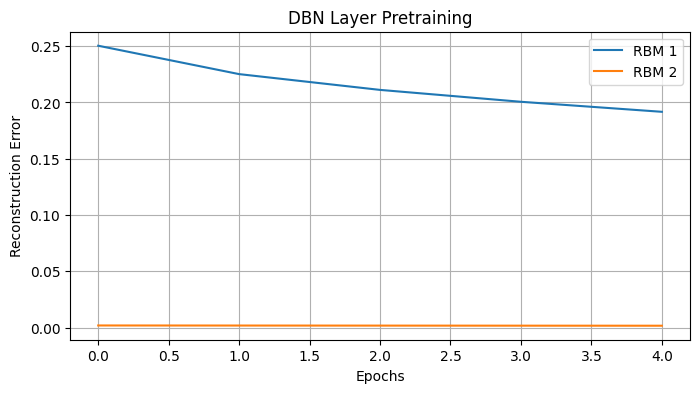

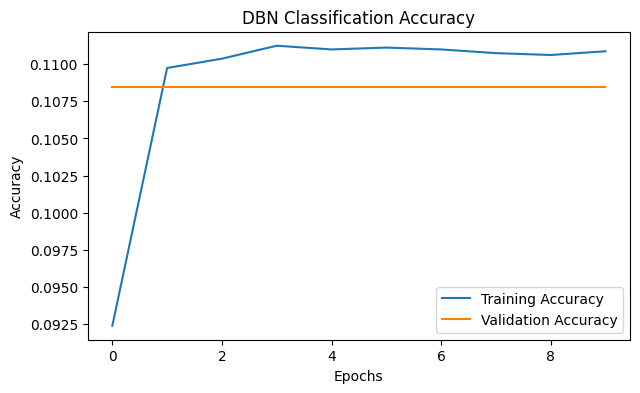

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from scipy.special import expit
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

# 1. Load MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

# 2. Normalize images
X_train = X_train[:10000].reshape(-1, 784) / 255.0
X_test = X_test[:2000].reshape(-1, 784) / 255.0

X_train = (X_train > 0.5).astype(float)
X_test = (X_test > 0.5).astype(float)

# 3. Define RBM parameters
def initialize_rbm(n_visible, n_hidden):

    W = np.random.normal(
        0, 0.01,
        (n_visible, n_hidden)
    )

    vb = np.zeros(n_visible)
    hb = np.zeros(n_hidden)

    return W, vb, hb

# 4. Train RBM
def train_rbm(X, n_hidden, epochs=5):

    W, vb, hb = initialize_rbm(
        X.shape[1],
        n_hidden
    )

    learning_rate = 0.01
    errors = []

    for epoch in range(epochs):

        # Positive phase
        ph = expit(X @ W + hb)

        # Sample hidden units
        h = (
            np.random.random(ph.shape) < ph
        ).astype(float)

        # Negative phase
        pv = expit(h @ W.T + vb)

        v = (
            np.random.random(pv.shape) < pv
        ).astype(float)

        nh = expit(v @ W + hb)

        # Update weights and biases
        W += learning_rate * (
            X.T @ ph - v.T @ nh
        ) / len(X)

        vb += learning_rate * np.mean(
            X - pv,
            axis=0
        )

        hb += learning_rate * np.mean(
            ph - nh,
            axis=0
        )

        error = np.mean((X - pv) ** 2)

        errors.append(error)

        print(
            f"Epoch {epoch+1}, Error: {error:.4f}"
        )

    return W, vb, hb, errors

# 5. Train first RBM
print("\nTRAINING FIRST RBM")

W1, vb1, hb1, errors1 = train_rbm(
    X_train,
    128
)

# 6. Extract first hidden representation
H1 = expit(X_train @ W1 + hb1)

print("\nFIRST REPRESENTATION SHAPE:", H1.shape)

# 7. Train second RBM
print("\nTRAINING SECOND RBM")

W2, vb2, hb2, errors2 = train_rbm(
    H1,
    64
)

# 8. Extract second hidden representation
H2 = expit(H1 @ W2 + hb2)

print("\nSECOND REPRESENTATION SHAPE:", H2.shape)

# 9. Build classification model
model = models.Sequential([
    layers.Input(shape=(784,)),

    layers.Dense(
        128,
        activation="sigmoid",
        trainable=False,
        name="RBM_Layer_1"
    ),

    layers.Dense(
        64,
        activation="sigmoid",
        trainable=False,
        name="RBM_Layer_2"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

# Transfer pretrained RBM weights
model.get_layer("RBM_Layer_1").set_weights([
    W1,
    hb1
])

model.get_layer("RBM_Layer_2").set_weights([
    W2,
    hb2
])

# 10. Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 11. Train output layer
history = model.fit(
    X_train,
    y_train[:10000],
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# 12. Evaluate model
loss, accuracy = model.evaluate(
    X_test,
    y_test[:2000],
    verbose=0
)

print("\nDBN PERFORMANCE")

print("Test Loss:", loss)

print("Test Accuracy:", accuracy)

# 13. Plot RBM errors
plt.figure(figsize=(8, 4))

plt.plot(errors1, label="RBM 1")

plt.plot(errors2, label="RBM 2")

plt.xlabel("Epochs")
plt.ylabel("Reconstruction Error")

plt.title("DBN Layer Pretraining")

plt.legend()
plt.grid()

plt.show()

# 14. Plot classification accuracy
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("DBN Classification Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()